# Mini-projet Séries Temporelles — TEK-UP 2026

**Modélisation, prévision et diagnostic de la série multidimensionnelle XOM / XLE**

Notebook principal en Python : il reproduit l'étude de bout en bout, sans intervention manuelle autre que l'exécution des cellules.
La logique est dans `src/` ; ce notebook appelle les fonctions et interprète les résultats.

| Partie | Langage |
| --- | --- |
| Sections 1–3 (données, EDA, ARIMA, VAR/VECM, GARCH) | Python **et** R (`notebooks/classical_R.Rmd`) |
| Section 4 (LSTM/GRU, hybride) et extensions | **Python uniquement** |

In [1]:
# Racine du projet retrouvée depuis le dossier courant : le notebook marche lancé
# depuis notebooks/ (Jupyter, nbconvert) comme depuis la racine (VS Code).
import sys
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "config.yaml").exists())
sys.path.insert(0, str(ROOT))

import warnings
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from src.utils import load_config, set_seed, print_versions, save_fig, save_table
from src import data

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

# Seed fixée dès le début : toute la suite (bootstrap, réseaux) devient reproductible.
set_seed()
# Versions affichées en tête : exigence de reproductibilité (cahier §9.1).
print_versions()

python         3.11.9
numpy          1.26.4
pandas         2.2.3
scipy          1.13.1
statsmodels    0.14.4
pmdarima       2.0.4
arch           7.0.0
scikit-learn   1.5.2
tensorflow     2.16.2
prophet        1.1.6
yfinance       0.2.66
matplotlib     3.9.2
seaborn        0.13.2
pyyaml         6.0.2


## 1. Données

### 1.1 Choix de la thématique

Nous retenons l'**option A — Finance** avec le couple **XOM (ExxonMobil) / XLE (Energy Select Sector SPDR ETF)** : une action et son indice sectoriel partagent un facteur commun, ce qui permet d'étudier cointégration et volatilité conditionnelle sur des épisodes de crise identifiables (krach pétrolier 2016, COVID 2020, guerre en Ukraine 2022).
Le **Brent** (`BZ=F`, contrat à terme ICE) est récupéré comme variable exogène pour les extensions (section 7).

Tous les paramètres sont lus dans `config.yaml` :

In [2]:
cfg = load_config()
pd.Series({
    "Source": cfg["data"]["source"],
    "Tickers": ", ".join(cfg["data"]["tickers"].values()),
    "Variable de prix": cfg["data"]["price_column"],
    "Période": f'{cfg["data"]["start"]} → {cfg["data"]["end"]} (incluse)',
    "Fréquence": "journalière, jours de bourse",
    "Split train": cfg["split"]["train_ratio"],
    "Seed": cfg["seed"],
}, name="paramètre").to_frame()

,paramètre
Source,Yahoo Finance
Tickers,"XOM, XLE, BZ=F"
Variable de prix,Adj Close
Période,2016-01-01 → 2025-12-31 (incluse)
Fréquence,"journalière, jours de bourse"
Split train,0.9000
Seed,42


### 1.2 Import des données

`data.load_raw()` lit d'abord le cache `data/raw/*.csv` et ne télécharge depuis Yahoo Finance (`yfinance`, `auto_adjust=False`) que si le fichier est absent.
Ce choix est essentiel pour la reproductibilité : Yahoo **recalcule l'`Adj Close` rétroactivement** à chaque nouveau dividende, si bien qu'un téléchargement fait un autre jour donnerait des prix ajustés légèrement différents. Le cache versionné fige l'échantillon étudié.
Pour forcer un nouveau téléchargement : `data.load_raw(refresh=True)`.

In [3]:
raw = data.load_raw()
for role, df in raw.items():
    print(f"{role:<10} {cfg['data']['tickers'][role]:<5} {df.shape[0]} lignes × {df.shape[1]} colonnes")

target     XOM   2514 lignes × 6 colonnes
sector     XLE   2514 lignes × 6 colonnes
exogenous  BZ=F  2515 lignes × 6 colonnes


### 1.3 Aperçu des données brutes

In [4]:
# Premières et dernières lignes de XOM : vérifie les bornes de la période et la cohérence des colonnes.
pd.concat([raw["target"].head(), raw["target"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,77.5000,77.9400,76.4600,77.4600,49.0023,20400100
2016-01-05,77.1900,78.1400,76.9200,78.1200,49.4198,11993500
2016-01-06,76.6400,77.6400,76.5900,77.4700,49.0086,18826900
2016-01-07,76.0600,77.9900,75.9000,76.2300,48.2242,21263800
2016-01-08,76.3500,76.6500,74.5000,74.6900,47.2500,19033600
2025-12-24,119.3300,120.0500,119.1200,119.2200,116.8754,6137400
2025-12-26,118.8900,119.5500,118.5300,119.1100,116.7676,8066100
2025-12-29,120.1500,121.3000,119.4000,120.5300,118.1596,14782500
2025-12-30,121.1000,121.8000,120.6300,120.9900,118.6106,11150500


In [5]:
pd.concat([raw["sector"].head(), raw["sector"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,30.0800,30.3900,29.6500,30.1500,19.6958,43617400
2016-01-05,30.1300,30.3000,29.7950,30.2650,19.7709,31058400
2016-01-06,29.5500,29.6100,28.8550,29.1000,19.0099,53924200
2016-01-07,28.5350,29.1900,28.2700,28.3900,18.5461,56163800
2016-01-08,28.6300,28.6950,27.9200,28.0250,18.3076,38454200
2025-12-24,44.4200,44.5600,44.3100,44.3700,43.5077,11293900
2025-12-26,44.3200,44.4400,43.9900,44.2000,43.3410,17884500
2025-12-29,44.5100,44.7400,44.2900,44.6200,43.7529,31352100
2025-12-30,44.8000,45.0900,44.8000,44.9600,44.0863,18654700


In [6]:
pd.concat([raw["exogenous"].head(), raw["exogenous"].tail()])

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
2016-01-04,37.4000,38.9900,36.7800,37.2200,37.2200,41288
2016-01-05,37.3200,37.5700,36.2500,36.4200,36.4200,29327
2016-01-06,36.7200,36.7200,34.1400,34.2300,34.2300,43019
2016-01-07,34.5200,34.7300,32.1800,33.7500,33.7500,44381
2016-01-08,33.8000,34.7300,32.7900,33.5500,33.5500,39985
2025-12-24,62.4300,62.7200,62.0200,62.2400,62.2400,14966
2025-12-26,62.3500,62.6900,60.5900,60.6400,60.6400,9687
2025-12-29,61.0400,62.1500,60.9500,61.9400,61.9400,9170
2025-12-30,61.7000,62.3300,61.5100,61.9200,61.9200,30567


**Ajustements appliqués par le fournisseur.** Sur Yahoo Finance, `Close` est déjà ajusté des **splits** ; `Adj Close` l'est en plus des **dividendes** (réinvestis). C'est donc `Adj Close` qui mesure le rendement total réellement obtenu par un investisseur, et c'est la variable retenue.
L'écart entre les deux colonnes se lit sur la première ligne de XOM : `Close` = 77,46 $ contre `Adj Close` = 49,00 $ le 2016-01-04, soit dix ans de dividendes cumulés réintégrés dans l'historique. Sur la dernière ligne (2025-12-31), l'écart n'est plus que de 120,34 $ contre 117,97 $ : l'ajustement diminue quand on se rapproche de la date de téléchargement.
Pour le Brent (contrat à terme), il n'y a pas de dividende : `Close` et `Adj Close` sont identiques. La série `BZ=F` raccorde des contrats successifs (échéance la plus proche) : un changement de contrat peut créer un petit saut de prix qui n'est pas un vrai rendement. C'est sans conséquence pour les sections 2 à 6, où le Brent n'intervient pas, et sera rappelé dans la section 7.

### 1.4 Valeurs manquantes et alignement des calendriers

In [7]:
miss = data.missing_report(raw)
save_table(miss, "tab01_manquants")
miss.T

rôle,target,sector,exogenous
ticker,XOM,XLE,BZ=F
début,2016-01-04,2016-01-04,2016-01-04
fin,2025-12-31,2025-12-31,2025-12-31
observations,2514,2514,2515
NaN Adj Close,0,0,0
NaN toutes colonnes,0,0,0
dates dupliquées,0,0,0
jours communs XOM/XLE absents,0,0,2
jours en plus du calendrier commun,0,0,3


In [8]:
# Jours précis où les calendriers diffèrent : on vérifie qu'il s'agit de jours fériés, pas d'erreurs.
common = raw["target"].index.intersection(raw["sector"].index)
brent = raw["exogenous"].index
print("Jours de bourse XOM/XLE sans cotation du Brent :", [d.date() for d in common.difference(brent)])
print("Cotations du Brent hors calendrier XOM/XLE     :", [d.date() for d in brent.difference(common)])

Jours de bourse XOM/XLE sans cotation du Brent : [datetime.date(2016, 10, 10), datetime.date(2016, 11, 11)]
Cotations du Brent hors calendrier XOM/XLE     : [datetime.date(2023, 11, 23), datetime.date(2025, 1, 9), datetime.date(2025, 7, 4)]


**Interprétation.**
- XOM et XLE ont exactement le même calendrier : **2 514 jours de bourse** du 2016-01-04 au 2025-12-31, sans aucune valeur manquante ni date dupliquée. La jointure interne ne supprime donc aucune observation.
- Le Brent cote sur ICE, avec un calendrier un peu différent :
  - il **manque 2 jours** de bourse américains (10 octobre et 11 novembre 2016) ;
  - il a **3 cotations en plus** les jours de fermeture de New York (Thanksgiving 2023, 9 janvier 2025 — journée de deuil national pour Jimmy Carter — et 4 juillet 2025).
- Le Brent est rattaché au calendrier XOM/XLE par jointure à gauche : les 3 jours en plus sont écartés, les 2 jours absents restent `NaN`.

**Pourquoi pas de remplissage (`ffill`) ?** Le calendrier boursier est irrégulier par nature (week-ends, jours fériés). Recopier le prix de la veille créerait des rendements **exactement nuls** qui n'ont jamais existé : ils réduiraient artificiellement la variance et biaiseraient l'estimation des modèles GARCH. Les modèles reçoivent donc la suite des jours de bourse comme un index positionnel ; les dates ne servent qu'aux graphiques et à l'interprétation.
Les 2 `NaN` du Brent ne concernent que la variable exogène, utilisée seulement en section 7 : ils seront traités à ce moment-là (suppression des 2 jours dans le modèle concerné).

### 1.5 Variables dérivées

`data.build_features()` construit, pour chaque actif, le log-prix, le log-rendement en %, la volatilité réalisée sur 21 jours annualisée et la moyenne mobile 50 jours (indicateurs techniques exigés par le cahier §1.1).
Toutes les fenêtres glissantes ne regardent que le passé : la valeur à la date *t* n'utilise que des données jusqu'à *t*, ce qui exclut toute fuite d'information du test vers le train.

In [9]:
var_table = data.variables_table()
save_table(var_table, "tab02_variables", index=False)
# Affichage sans troncature : les définitions sont reprises telles quelles dans le rapport.
var_table.style.hide(axis="index").set_properties(**{"text-align": "left"})

variable,rôle,définition,unité
XOM_price,target,"Prix de clôture ajusté (dividendes, splits) de XOM",USD
XOM_logp,target,Log-prix l_t = ln(P_t),log(USD)
XOM_ret,target,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XOM_vol21,target,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XOM_ma50,target,Moyenne mobile de P_t sur 50 jours,USD
XLE_price,sector,"Prix de clôture ajusté (dividendes, splits) de XLE",USD
XLE_logp,sector,Log-prix l_t = ln(P_t),log(USD)
XLE_ret,sector,Log-rendement r_t = 100 × ln(P_t / P_{t-1}),%
XLE_vol21,sector,Volatilité réalisée : √252 × écart-type glissant de r_t sur 21 jours,% annualisé
XLE_ma50,sector,Moyenne mobile de P_t sur 50 jours,USD


In [10]:
panel = data.build_features(data.align_prices(raw))
print(f"Panel : {panel.shape[0]} dates × {panel.shape[1]} variables, "
      f"du {panel.index.min().date()} au {panel.index.max().date()}")
print(f"Type d'index : {type(panel.index).__name__}")
# Fréquence : jours ouvrés théoriques vs jours de bourse réels (les fériés manquent).
bdays = pd.bdate_range(panel.index.min(), panel.index.max())
print(f"Fréquence déclarée : jours de bourse (config.yaml : '{cfg['data']['frequency']}')")
print(f"Jours ouvrés théoriques : {len(bdays)} ; jours de bourse réels : {len(panel)} ; "
      f"jours fériés de bourse : {len(bdays.difference(panel.index))}")
panel.head(3)

Panel : 2514 dates × 15 variables, du 2016-01-04 au 2025-12-31
Type d'index : DatetimeIndex
Fréquence déclarée : jours de bourse (config.yaml : 'B')
Jours ouvrés théoriques : 2608 ; jours de bourse réels : 2514 ; jours fériés de bourse : 94


,XOM_price,XOM_logp,XOM_ret,XOM_vol21,XOM_ma50,XLE_price,XLE_logp,XLE_ret,XLE_vol21,XLE_ma50,BZ=F_price,BZ=F_logp,BZ=F_ret,BZ=F_vol21,BZ=F_ma50
Date,,,,,,,,,,,,,,,
2016-01-04,49.0023,3.8919,NaN,NaN,NaN,19.6958,2.9804,NaN,NaN,NaN,37.2200,3.6168,NaN,NaN,NaN
2016-01-05,49.4198,3.9004,0.8484,NaN,NaN,19.7709,2.9842,0.3807,NaN,NaN,36.4200,3.5951,-2.1728,NaN,NaN
2016-01-06,49.0086,3.8920,-0.8355,NaN,NaN,19.0099,2.9450,-3.9254,NaN,NaN,34.2300,3.5331,-6.2016,NaN,NaN


**Fréquence de la série.** La série est journalière au rythme des **jours de bourse** du NYSE. On ne fixe pas `freq="B"` sur l'index pandas : cela réinsérerait les jours fériés de bourse (Thanksgiving, Noël, etc.) sous forme de lignes vides, qu'il faudrait ensuite remplir artificiellement — exactement ce qu'on a écarté plus haut.
L'index reste donc un `DatetimeIndex` des dates réellement cotées. La fréquence est déclarée dans `config.yaml` et rappelée aux modèles : par exemple la saisonnalité hebdomadaire testée en SARIMA aura s = 5 jours de bourse, et l'annualisation de la volatilité se fait avec 252 jours.

In [11]:
# NaN attendus en début de série (fenêtres glissantes) : à distinguer de vrais manquants.
na = panel.isna().sum().rename("NaN").to_frame()
na["origine"] = ["aucun" if n == 0 else "" for n in na["NaN"]]
w, m = cfg["features"]["realized_vol_window"], cfg["features"]["moving_average_window"]
for c in na.index:
    if c.startswith(("XOM", "XLE")):
        na.loc[c, "origine"] = {"_ret": "1er jour (pas de veille)", "_vol21": f"{w} premiers jours (fenêtre)",
                                "_ma50": f"{m - 1} premiers jours (fenêtre)"}.get(c[c.index("_"):], "aucun")
    elif c.endswith(("_price", "_logp")):
        na.loc[c, "origine"] = "2 jours sans cotation du Brent"
    else:
        na.loc[c, "origine"] = "début de série + 2 jours sans cotation du Brent, propagés par la fenêtre"
na

,NaN,origine
XOM_price,0,aucun
XOM_logp,0,aucun
XOM_ret,1,1er jour (pas de veille)
XOM_vol21,21,21 premiers jours (fenêtre)
XOM_ma50,49,49 premiers jours (fenêtre)
XLE_price,0,aucun
XLE_logp,0,aucun
XLE_ret,1,1er jour (pas de veille)
XLE_vol21,21,21 premiers jours (fenêtre)
XLE_ma50,49,49 premiers jours (fenêtre)


**Lecture.** Pour XOM et XLE, les `NaN` sont uniquement mécaniques : 1 pour le rendement (pas de veille le premier jour), 21 pour la volatilité réalisée (le premier écart-type sur 21 rendements n'est disponible qu'au 22ᵉ jour) et 49 pour la moyenne mobile 50 jours.
Pour le Brent, chacun des 2 jours absents se propage : il manque 2 prix, mais 5 rendements (le jour absent et le lendemain, plus le premier jour), et davantage pour les variables fenêtrées.

### 1.6 Découpage chronologique train / test (90 / 10)

La coupure se fait sur l'ordre des dates, jamais par tirage aléatoire : le test doit être strictement postérieur au train, comme dans une vraie situation de prévision. Toute normalisation (section 4) sera ajustée sur le train uniquement.

In [12]:
train, test = data.train_test_split_time(panel)
split = pd.DataFrame({
    "observations": [len(train), len(test)],
    "part": [len(train) / len(panel), len(test) / len(panel)],
    "début": [train.index.min().date(), test.index.min().date()],
    "fin": [train.index.max().date(), test.index.max().date()],
}, index=["train", "test"])
save_table(split, "tab03_split")

# Sauvegarde des séries préparées : les sections suivantes et le notebook R repartent de ces fichiers.
_ = data.prepare(save=True)
split

,observations,part,début,fin
train,2262,0.8998,2016-01-04,2024-12-27
test,252,0.1002,2024-12-30,2025-12-31


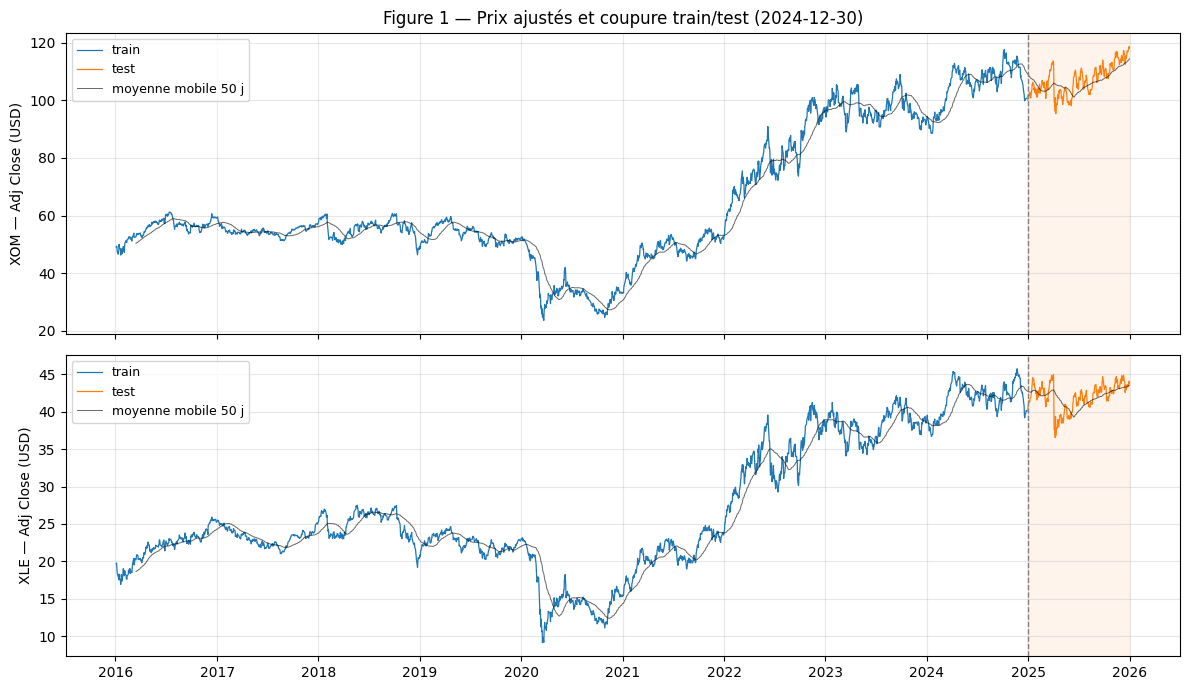

In [13]:
cut = test.index[0]
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)
for ax, tk in zip(axes, ["XOM", "XLE"]):
    ax.plot(train.index, train[f"{tk}_price"], color="tab:blue", lw=0.9, label="train")
    ax.plot(test.index, test[f"{tk}_price"], color="tab:orange", lw=0.9, label="test")
    ax.plot(panel.index, panel[f"{tk}_ma50"], color="black", lw=0.7, alpha=0.6, label="moyenne mobile 50 j")
    ax.axvspan(cut, panel.index[-1], color="tab:orange", alpha=0.08)
    ax.axvline(cut, color="grey", ls="--", lw=1)
    ax.set_ylabel(f"{tk} — Adj Close (USD)")
    ax.legend(loc="upper left", fontsize=9)
    ax.grid(alpha=0.3)
axes[0].set_title(f"Figure 1 — Prix ajustés et coupure train/test ({cut.date()})")
axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 1, "prix_train_test")
plt.show()

**Interprétation de la figure 1.**
- **Découpage.** Le train couvre **2 262 jours** (2016-01-04 → 2024-12-27), le test les **252 jours suivants** (2024-12-30 → 2025-12-31), soit environ une année de bourse complète.
- **Évolution des prix.** Les deux séries suivent la même trajectoire générale, avec deux ruptures nettes :
  - l'effondrement de 2020 (COVID, chute de la demande de pétrole) ;
  - la forte hausse de 2021–2022 (reprise puis guerre en Ukraine).

  Le parallélisme visuel entre XOM et XLE (corrélation des rendements journaliers : 0,914 sur toute la période) motive le test de cointégration de la section 3.2.
- **Conséquence pour la modélisation.** Le niveau des prix n'est manifestement pas stationnaire (tendance et ruptures). Les tests ADF/KPSS de la section 2 vérifieront formellement l'ordre d'intégration.
- **Point de vigilance : le test est plus calme que le train.** Le test contient bien un choc (chute brutale début avril 2025, visible sur les deux actifs), mais il est d'une ampleur sans commune mesure avec 2020 :

  | | Train | Test |
  | --- | --- | --- |
  | Écart-type des rendements XOM | 1,78 % | 1,48 % |
  | Volatilité réalisée maximale XOM | 108,9 % | 47,4 % |
  | Volatilité réalisée maximale XLE | 149,9 % | 61,1 % |

  Les erreurs de prévision mesurées sur le test seront donc conditionnelles à ce régime et ne se généraliseront pas automatiquement à une période de crise. On en tiendra compte dans la discussion des limites.

## 2. Analyse exploratoire

**Échantillon utilisé.** Les graphiques descriptifs couvrent toute la période. En revanche, tous les tests et outils qui servent à **choisir un modèle** (statistiques descriptives, ACF/PACF, STL, ADF/KPSS) sont calculés sur le **train uniquement** : identifier un modèle avec des données du test serait une fuite d'information.

In [14]:
from src import eda
from IPython.display import display

TRAIN = train  # 2 262 jours, 2016-01-04 → 2024-12-27
# Épisodes de crise repérés sur la figure 1, réutilisés pour annoter les graphiques.
CRISES = {"COVID-19": ("2020-02-20", "2020-04-30"), "Guerre en Ukraine": ("2022-02-24", "2022-06-30")}

def shade(ax, legend=False):
    for (name, (a, b)), color in zip(CRISES.items(), ["tab:red", "tab:purple"]):
        ax.axvspan(pd.Timestamp(a), pd.Timestamp(b), color=color, alpha=0.12, label=name if legend else None)
    ax.axvspan(test.index[0], test.index[-1], color="tab:orange", alpha=0.08, label="test" if legend else None)

### 2.1 Visualisation des séries

Les deux prix n'ont pas la même échelle (XOM ≈ 49 $ et XLE ≈ 20 $ en 2016) : on les ramène en **base 100** au 2016-01-04 pour comparer leurs trajectoires. On trace ensuite les rendements et la volatilité réalisée.

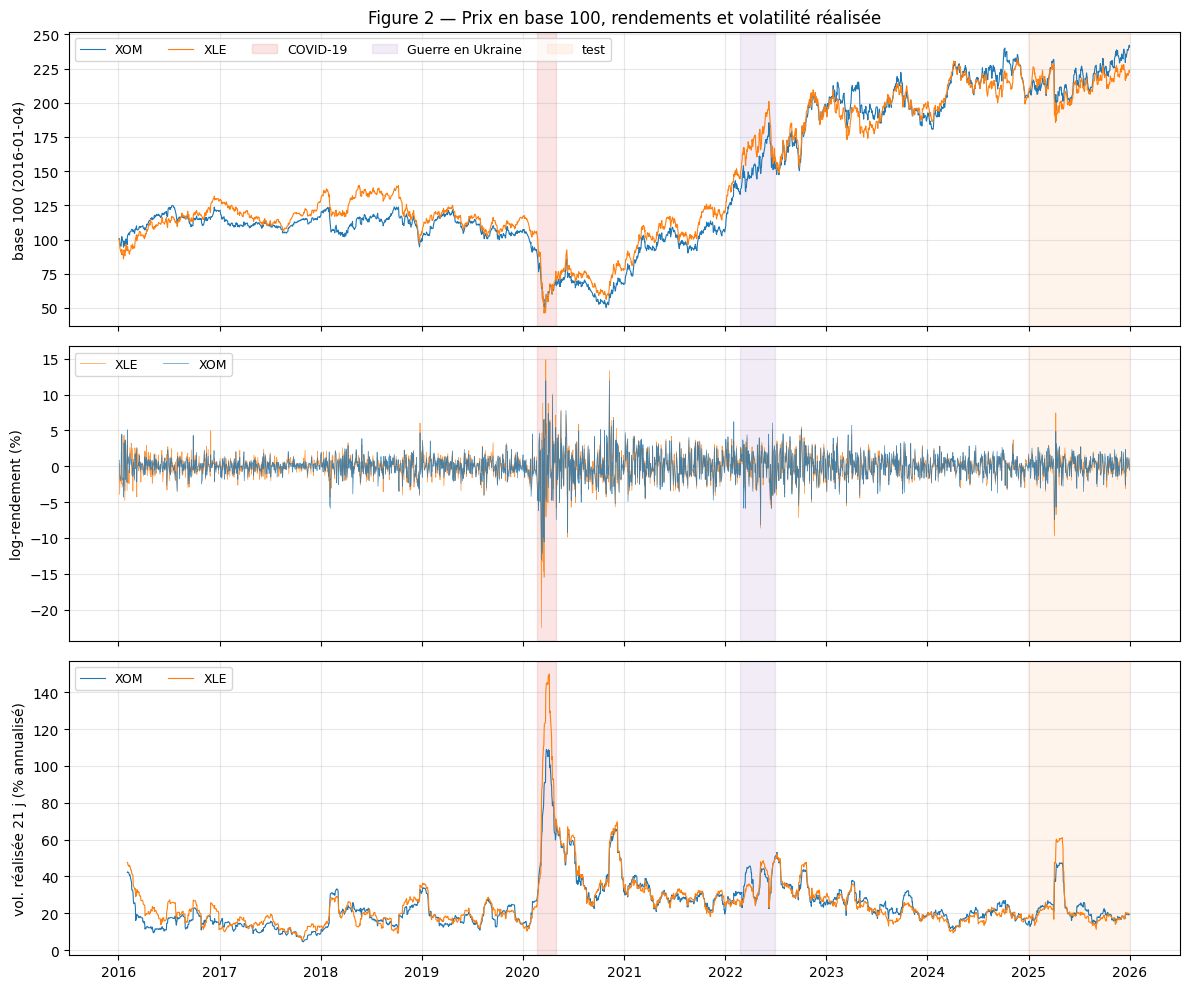

Performance totale 2016-2025 (dividendes réinvestis) : XOM 140.8 %, XLE 122.6 %
Creux et pics de volatilité réalisée :
  XOM : max 108.9 % le 2020-03-26 ; médiane 21.6 %
  XLE : max 149.9 % le 2020-04-06 ; médiane 21.2 %


In [15]:
fig, axes = plt.subplots(3, 1, figsize=(12, 10), sharex=True)
base = panel[["XOM_price", "XLE_price"]] / panel[["XOM_price", "XLE_price"]].iloc[0] * 100
axes[0].plot(base.index, base["XOM_price"], lw=0.8, label="XOM")
axes[0].plot(base.index, base["XLE_price"], lw=0.8, label="XLE")
axes[0].set_ylabel("base 100 (2016-01-04)")
axes[1].plot(panel.index, panel["XLE_ret"], lw=0.5, color="tab:orange", alpha=0.8, label="XLE")
axes[1].plot(panel.index, panel["XOM_ret"], lw=0.5, color="tab:blue", alpha=0.8, label="XOM")
axes[1].set_ylabel("log-rendement (%)")
axes[2].plot(panel.index, panel["XOM_vol21"], lw=0.8, label="XOM")
axes[2].plot(panel.index, panel["XLE_vol21"], lw=0.8, label="XLE")
axes[2].set_ylabel("vol. réalisée 21 j (% annualisé)")
for i, ax in enumerate(axes):
    shade(ax, legend=(i == 0))
    ax.grid(alpha=0.3)
    ax.legend(loc="upper left", fontsize=9, ncol=5)
axes[0].set_title("Figure 2 — Prix en base 100, rendements et volatilité réalisée")
axes[2].xaxis.set_major_locator(mdates.YearLocator())
axes[2].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
fig.tight_layout()
save_fig(fig, 2, "series_rendements_volatilite")
plt.show()

perf = (base.iloc[-1] - 100).round(1)
print(f"Performance totale 2016-2025 (dividendes réinvestis) : XOM {perf['XOM_price']} %, XLE {perf['XLE_price']} %")
print("Creux et pics de volatilité réalisée :")
for tk in ["XOM", "XLE"]:
    v = panel[f"{tk}_vol21"]
    print(f"  {tk} : max {v.max():.1f} % le {v.idxmax().date()} ; médiane {v.median():.1f} %")

**Interprétation de la figure 2.**
- **Prix (base 100).** Sur 2016–2025, XOM progresse de **+140,8 %** et XLE de **+122,6 %** (dividendes réinvestis). Les deux trajectoires restent très proches, ce qui est attendu puisque XOM est l'une des plus grosses positions de l'ETF XLE. Deux ruptures se détachent :
  - le **krach de 2020**, où les deux actifs perdent environ la moitié de leur valeur ;
  - la **hausse de 2021–2022**, qui porte les prix à environ 200, soit le double de 2016.

  Ni l'un ni l'autre ne revient vers un niveau moyen fixe : visuellement, les prix ne sont pas stationnaires.
- **Rendements.** Au contraire des prix, ils oscillent autour de zéro sans tendance : ils ont l'allure d'une série stationnaire **en moyenne**. En revanche, leur amplitude varie fortement dans le temps :
  - une phase très calme en 2017 ;
  - une explosion en mars 2020, avec des chutes de −13 % (XOM) et −22,5 % (XLE) en une journée ;
  - une agitation durable en 2020–2022.

  C'est le phénomène de **regroupement de volatilité** (*volatility clustering*) : les fortes variations se suivent, les faibles aussi.
- **Volatilité réalisée.**
  - **Valeurs habituelles.** La médiane est de 21,6 % (XOM) et 21,2 % (XLE).
  - **Pics de mars–avril 2020.** La volatilité monte à **108,9 %** pour XOM (2020-03-26) et **149,9 %** pour XLE (2020-04-06), soit environ cinq fois la normale.
  - **2022.** L'agitation commence avec l'invasion de l'Ukraine (zone violette). Le pic de l'année arrive un peu plus tard (≈ 53 % pour les deux actifs le 2022-07-07) et reste deux à trois fois plus faible qu'en 2020.
  - **Avril 2025, dans le test.** On observe aussi un pic, autour de 50 à 60 %.
- **Conséquences pour la suite.** La moyenne des rendements semble stable, mais leur variance ne l'est pas. Il faudra donc :
  - modéliser le niveau en différences (à confirmer par ADF/KPSS en 2.6) ;
  - modéliser la variance conditionnelle avec un GARCH (section 3.3).

### 2.2 Statistiques descriptives des rendements (train)

Ces statistiques servent aussi d'entrée au prompt LLM de la section 5.

In [16]:
desc = eda.descriptive_stats(TRAIN[["XOM_ret", "XLE_ret"]])
save_table(desc, "tab04_stats_descriptives")
desc

,XOM_ret,XLE_ret
n,2261.0000,2261.0000
moyenne,0.0319,0.0315
écart-type,1.7845,1.9216
variance,3.1846,3.6925
skewness,-0.1630,-0.8902
excès de kurtosis,6.6224,16.4357
min,-13.0391,-22.4910
max,11.9442,14.8741
Jarque-Bera,4141.6970,25747.3428
p-value JB,0.0000,0.0000


**Interprétation des statistiques descriptives (train, 2 261 rendements).**

**Moyenne.** Le rendement moyen est de 0,032 % par jour, soit environ **8 % par an** pour les deux actifs (0,0319 × 252 et 0,0315 × 252). Il est minuscule face à l'écart-type journalier de 1,78 % (XOM) et 1,92 % (XLE), soit une volatilité annualisée de 28,3 % et 30,5 %. La statistique t de la moyenne vaut 0,0319 / (1,7845 / √2 261) ≈ **0,85** pour XOM (0,78 pour XLE) : la moyenne **n'est pas significativement différente de zéro**. Ce calcul suppose des rendements i.i.d. ; il est refait ci-dessous avec un écart-type robuste. On s'attend donc à ce que la constante (dérive) soit non significative dans les modèles ARIMA.

**Asymétrie.**
- Elle est négative pour les deux actifs : les fortes baisses sont plus marquées que les fortes hausses.
- Elle est faible pour XOM (skewness de −0,16) mais nette pour XLE (−0,89).
- Le minimum de XLE (−22,5 %) est bien plus extrême que son maximum (+14,9 %).

**Queues épaisses.** L'excès de kurtosis vaut **6,6** pour XOM et **16,4** pour XLE, contre 0 pour une loi normale. Les rendements extrêmes sont donc beaucoup plus fréquents que ne le prévoit une loi gaussienne.

**Normalité.** Le test de Jarque-Bera rejette très largement la normalité (JB = 4 142 pour XOM, 25 747 pour XLE ; p < 0,0001).

**Conséquences pour la modélisation.**
1. Les intervalles de prévision gaussiens des modèles ARIMA/VAR **sous-estimeront le risque de mouvements extrêmes**.
2. Le GARCH sera estimé avec une **loi de Student**, dont les queues épaisses sont adaptées.
3. Les tests de normalité des résidus rejetteront très probablement aussi. C'est attendu, et ne suffira pas à disqualifier un modèle.

In [17]:
# Le t classique suppose une variance constante, contredite par la figure 2 :
# on le recalcule avec un écart-type HAC (Newey-West), robuste à l'hétéroscédasticité et à l'autocorrélation.
mean_tests = pd.concat({tk: eda.mean_test(TRAIN[f"{tk}_ret"]) for tk in ["XOM", "XLE"]})
save_table(mean_tests, "tab04b_test_moyenne_hac")
mean_tests

moyenne  écart-type  statistique t  p-value
XOM classique (i.i.d.)           0.0319      0.0375         0.8487   0.3961
    HAC Newey-West (7 retards)   0.0319      0.0372         0.8561   0.3919
XLE classique (i.i.d.)           0.0315      0.0404         0.7786   0.4363
    HAC Newey-West (7 retards)   0.0315      0.0412         0.7630   0.4455

**Interprétation du test de moyenne robuste.**

**Pourquoi un écart-type robuste.** La statistique t précédente suppose des rendements indépendants et de variance constante, ce que contredit la figure 2. On refait donc le test H₀ : « rendement moyen nul » avec un écart-type **HAC de Newey-West** (7 retards, selon la règle usuelle ⌊4 (n/100)^(2/9)⌋), robuste à l'hétéroscédasticité et à l'autocorrélation.

**Résultat.** La conclusion ne change pas :

| | t classique | t HAC | p-value HAC |
| --- | --- | --- | --- |
| XOM | 0,85 | 0,86 | 0,39 |
| XLE | 0,78 | 0,76 | 0,45 |

La moyenne n'est pas significativement différente de zéro.

**Pourquoi les deux versions diffèrent si peu.** Pour une moyenne simple, la correction d'hétéroscédasticité seule ne modifie presque pas l'écart-type : elle compte surtout quand la variance est corrélée à un régresseur, ce qui n'est pas le cas ici. Et l'autocorrélation des rendements est trop faible pour peser.

**Conséquence.** Une dérive (constante) non significative est attendue dans les modèles ARIMA de la section 3.

### 2.3 Autocorrélations (ACF / PACF)

On examine trois transformations, dans l'ordre du plan : le **log-prix** (série brute), le **rendement** (série différenciée, puisque r_t = 100 × Δ ln P_t) et le **rendement au carré** (proxy de la variance). La bande bleue est l'intervalle de confiance à 95 % sous l'hypothèse de bruit blanc (≈ ±1,96/√n = ±0,041) : sur 40 retards, environ 2 la dépassent par pur hasard.

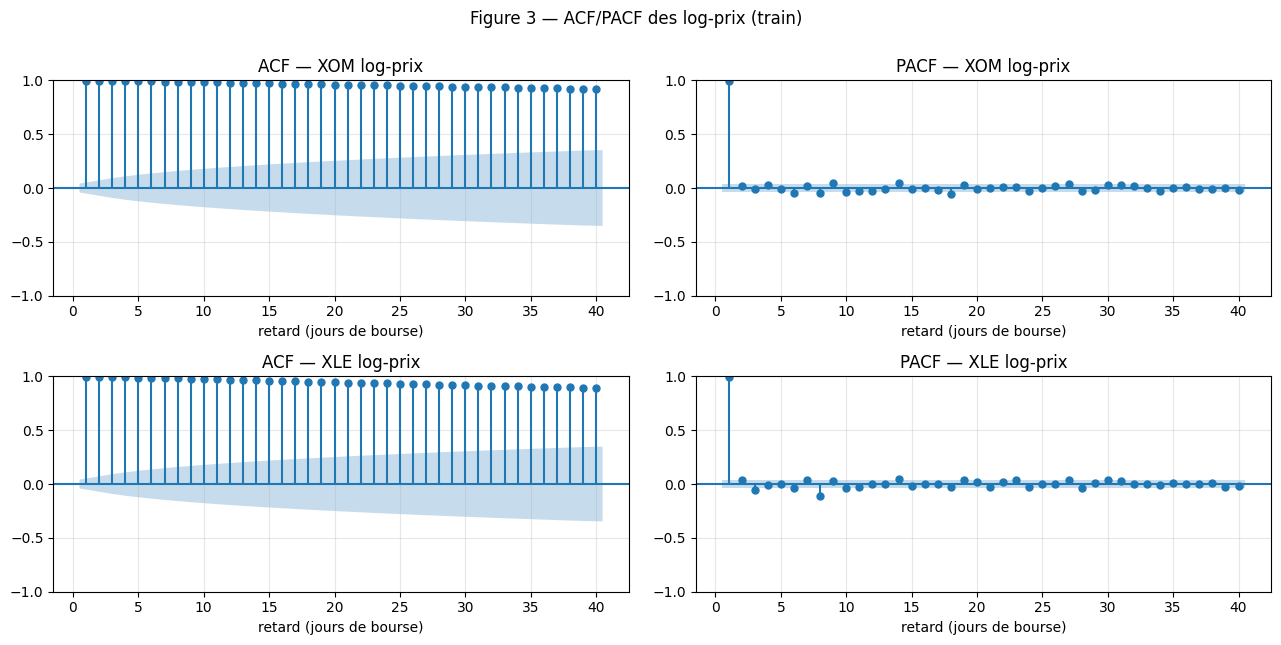

,XOM log-prix,XLE log-prix
n,2262,2262
bande 95 %,0.0412,0.0412
ACF(1),0.9982,0.9977
ACF(2),0.9965,0.9955
ACF(5),0.9913,0.9883
ACF(10),0.9820,0.9748
ACF(21),0.9589,0.9421
PACF(1),0.9982,0.9977
PACF(2),0.0176,0.0339
PACF(5),-0.0094,-0.0018


In [18]:
LAGS = 40
def acf_table(series):
    t = pd.DataFrame({name: eda.acf_summary(x, LAGS) for name, x in series.items()})
    return t

fig = eda.plot_acf_pacf({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]}, LAGS,
                        "Figure 3 — ACF/PACF des log-prix (train)")
save_fig(fig, 3, "acf_pacf_logprix")
plt.show()
acf_logp = acf_table({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]})
acf_logp

**Interprétation de la figure 3 (log-prix).**
- **ACF.** L'autocorrélation est quasi égale à 1 et décroît très lentement, de façon presque linéaire :
  - ACF(1) = 0,998 pour XOM (0,998 pour XLE) ;
  - ACF(21) = 0,959 (0,942), soit un mois plus tard ;
  - les **40 retards** restent tous très au-dessus de la bande de confiance.

  Cette décroissance lente est la signature d'une série **non stationnaire** : un choc ne s'efface pas, il se propage durablement au niveau des prix.
- **PACF.** Un seul pic, au retard 1 (0,998), puis plus rien : PACF(2) = 0,018 pour XOM (0,034 pour XLE). La série se comporte donc comme un AR(1) de coefficient ≈ 1, c'est-à-dire comme une **marche aléatoire** : l_t ≈ l_{t−1} + choc. Quelques retards partiels dépassent légèrement la bande (6 pour XOM, 5 pour XLE), mais avec des valeurs de 0,05 au plus, donc sans importance pratique.
- **Bande de confiance.** Sur le graphe ACF, la bande s'élargit avec le retard (formule de Bartlett). Le décompte « hors bande » du tableau utilise la bande fixe de bruit blanc (±0,041).
- **Ljung-Box.** Q(10) = 22 255 pour XOM (p < 0,0001) : l'absence d'autocorrélation est rejetée sans ambiguïté.

**Conclusion.** Le log-prix ne peut pas être modélisé tel quel par un ARMA stationnaire : il faut le différencier, ce que l'on vérifie sur la figure 4 et formellement en 2.6.

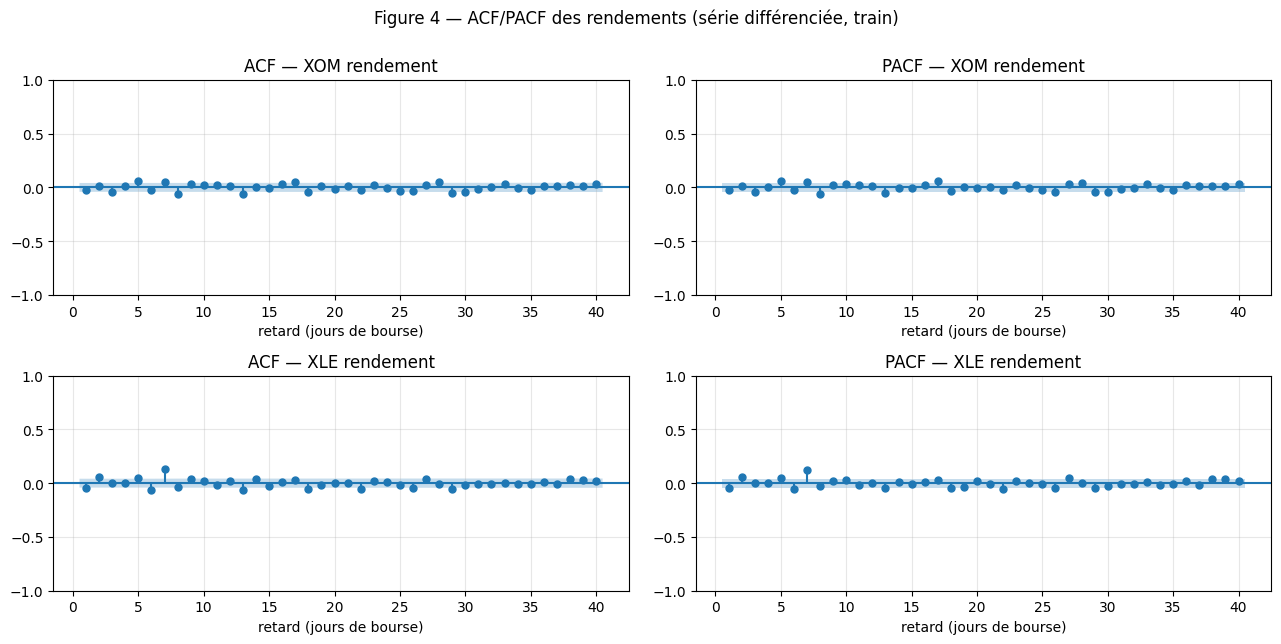

,XOM rendement,XLE rendement
n,2261,2261
bande 95 %,0.0412,0.0412
ACF(1),-0.0240,-0.0455
ACF(2),0.0140,0.0575
ACF(5),0.0579,0.0446
ACF(10),0.0262,0.0202
ACF(21),0.0164,-0.0005
PACF(1),-0.0240,-0.0455
PACF(2),0.0134,0.0556
PACF(5),0.0595,0.0450


In [19]:
fig = eda.plot_acf_pacf({"XOM rendement": TRAIN["XOM_ret"], "XLE rendement": TRAIN["XLE_ret"]}, LAGS,
                        "Figure 4 — ACF/PACF des rendements (série différenciée, train)")
save_fig(fig, 4, "acf_pacf_rendements")
plt.show()
acf_ret = acf_table({"XOM rendement": TRAIN["XOM_ret"], "XLE rendement": TRAIN["XLE_ret"]})
acf_ret

**Interprétation de la figure 4 (rendements = log-prix différencié).**
- **La structure de la figure 3 a disparu.** Une seule différenciation suffit à supprimer la persistance des niveaux. Les autocorrélations sont minuscules : la plus forte en valeur absolue vaut −0,064 (retard 8) pour XOM et 0,129 (retard 7) pour XLE. Une autocorrélation de 0,06 n'explique que 0,06² ≈ 0,4 % de la variance du rendement du lendemain.
- **Pas d'ordre ARMA lisible.** Ni l'ACF ni la PACF ne montrent de coupure nette après quelques retards :
  - les rares dépassements sont dispersés (XOM : retards 5, 7, 8, 13, 17, 28, 29, 30 ; XLE : 1, 2, 5, 6, 7, 13, 18, 22, 29) ;
  - aucun motif régulier ne s'en dégage.
- **Mais Ljung-Box rejette l'absence d'autocorrélation**, avec Q(10) = 34,9 pour XOM (p = 0,0001) et 70,1 pour XLE (p < 0,0001). Il y a 8 et 9 retards hors bande sur 40, alors qu'on en attend environ 2 par hasard. Avant d'en conclure qu'il existe une structure ARMA à exploiter, on vérifie d'où vient ce rejet dans le tableau suivant.

In [20]:
# Le rejet de Ljung-Box vient-il de la moyenne ou de la variance ? Trois versions des rendements.
robust = pd.concat({tk: eda.ljungbox_robustness(TRAIN[f"{tk}_ret"]) for tk in ["XOM", "XLE"]})
save_table(robust, "tab05_ljungbox_robustesse")
robust

p-value Q(5)  p-value Q(10)  p-value Q(20)
XOM rendements bruts                              0.0219         0.0001         0.0000
    standardisés par la vol. passée (21 j)        0.9714         0.9822         0.8980
    hors année 2020                               0.5890         0.4435         0.3595
XLE rendements bruts                              0.0050         0.0000         0.0000
    standardisés par la vol. passée (21 j)        0.4983         0.5343         0.7385
    hors année 2020                               0.6857         0.5099         0.8452

**Interprétation du contrôle de robustesse de Ljung-Box.**
Le test de Ljung-Box suppose une variance constante. Avec du regroupement de volatilité, quelques jours très agités suffisent à produire de grandes autocorrélations empiriques, et le test rejette trop souvent. On le refait donc sur deux versions corrigées des rendements :

| Version des rendements | XOM : p-value Q(10) | XLE : p-value Q(10) |
| --- | --- | --- |
| bruts | 0,0001 | < 0,0001 |
| divisés par leur volatilité des 21 jours précédents | **0,98** | **0,53** |
| sans l'année 2020 | **0,44** | **0,51** |

Le rejet **disparaît entièrement** dans les deux versions corrigées, pour Q(5), Q(10) et Q(20). Même le retard 7 de XLE, le plus marqué (0,129), tombe à 0,0008 sans 2020.

**Conclusion.**
- L'autocorrélation apparente des rendements est un **artefact de l'hétéroscédasticité de 2020**, pas une dynamique exploitable de la moyenne.
- En moyenne, les rendements sont compatibles avec un **bruit blanc**. Le log-prix est donc proche d'une marche aléatoire, et ARIMA(0,1,0) est le candidat de référence. Il sera comparé en 3.1 à des ARIMA(p,1,q) de petits ordres (p, q ≤ 2) et au choix d'`auto_arima`.
- Il faudra s'attendre à ce que les termes AR/MA éventuellement retenus aient un pouvoir prédictif très faible.

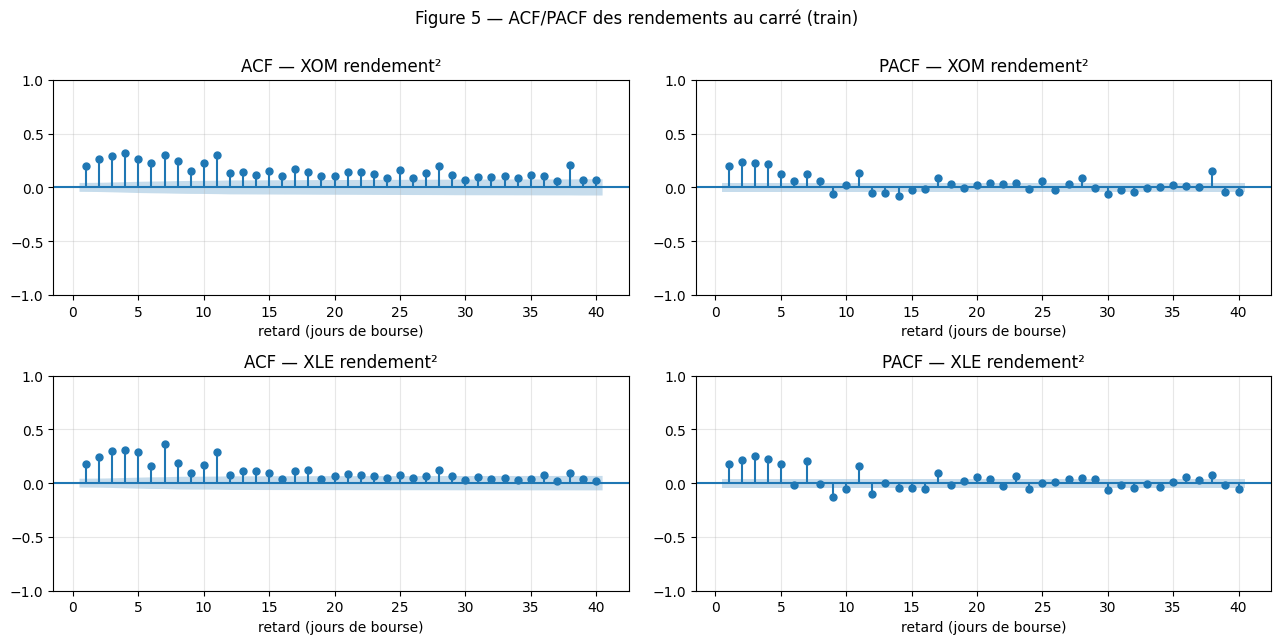

,XOM rendement²,XLE rendement²
n,2261,2261
bande 95 %,0.0412,0.0412
ACF(1),0.2028,0.1772
ACF(2),0.2673,0.2397
ACF(5),0.2645,0.2934
ACF(10),0.2227,0.1677
ACF(21),0.1434,0.0840
PACF(1),0.2028,0.1772
PACF(2),0.2359,0.2151
PACF(5),0.1256,0.1785


In [21]:
sq = {"XOM rendement²": TRAIN["XOM_ret"] ** 2, "XLE rendement²": TRAIN["XLE_ret"] ** 2}
fig = eda.plot_acf_pacf(sq, LAGS, "Figure 5 — ACF/PACF des rendements au carré (train)")
save_fig(fig, 5, "acf_pacf_rendements_carres")
plt.show()
acf_sq = acf_table(sq)
save_table(pd.concat([acf_logp, acf_ret, acf_sq], axis=1), "tab06_acf_resume")
acf_sq

**Interprétation de la figure 5 (rendements au carré).**
- **Le contraste avec la figure 4 est total.** Les rendements eux-mêmes sont quasi non autocorrélés, mais leurs carrés le sont fortement et durablement :
  - **XOM** : ACF(1) = 0,20 ; maximum 0,32 au retard 4 ; ACF(40) encore égale à 0,065 ; les **40 retards** dépassent la bande ;
  - **XLE** : maximum 0,37 au retard 7 ; 32 retards sur 40 hors bande ;
  - **Ljung-Box** : Q(10) = 1 464 pour XOM et 1 343 pour XLE (p < 0,0001).
- **Lecture économique.** Un jour de forte variation, dans un sens ou dans l'autre, est suivi d'autres jours de forte variation : c'est la mesure chiffrée du regroupement de volatilité de la figure 2. La décroissance lente de l'ACF indique une volatilité **très persistante**.
- **Implication pour le modèle.** La PACF des carrés est significative sur les ~5 premiers retards (entre 0,13 et 0,25), ce qui correspondrait à un ARCH d'ordre élevé. Un **GARCH(1,1)** représente cette dynamique de façon beaucoup plus parcimonieuse : la variance d'aujourd'hui dépend du choc d'hier **et** de la variance d'hier. Ce diagnostic justifie la section 3.3.
- **Un rendement non autocorrélé n'est pas un rendement indépendant.** Ces rendements sont imprévisibles en moyenne (figure 4), mais leur amplitude est en partie prévisible.

### 2.4 Décomposition STL du log-prix (train)

STL (Seasonal-Trend decomposition using Loess) en version **robuste**, pour que les chocs de 2020 ne déforment pas la tendance et la saisonnalité. On décompose le log-prix, et non le prix, pour que les composantes soient additives : une variation de la composante correspond à un pourcentage du prix.
Trois périodes sont testées : **5** (semaine de bourse), **21** (mois de bourse) et **252** (année de bourse). Pour juger objectivement la saisonnalité, on calcule la **force** de chaque composante (Wang, Smith & Hyndman, 2006) : F = max(0, 1 − Var(résidu) / Var(composante + résidu)). F proche de 0 signifie une composante inexistante, F proche de 1 une composante dominante.

In [22]:
strength = pd.DataFrame({(tk, p): eda.stl_strength(eda.stl_decompose(TRAIN[f"{tk}_logp"], p))
                         for tk in ["XOM", "XLE"] for p in (5, 21, 252)}).T
strength.index.names = ["actif", "période"]
save_table(strength, "tab07_stl_force")
strength

force tendance F_T  force saisonnalité F_S  amplitude saisonnière (max - min)  écart-type résidu
actif période                                                                                                  
XOM   5                    0.9968                  0.0000                             0.0978             0.0201
      21                   0.9912                  0.0319                             0.1313             0.0332
      252                  0.8686                  0.0000                             0.4105             0.1283
XLE   5                    0.9955                  0.0000                             0.2300             0.0218
      21                   0.9859                  0.0199                             0.1466             0.0386
      252                  0.8559                  0.0012                             0.3169             0.1231

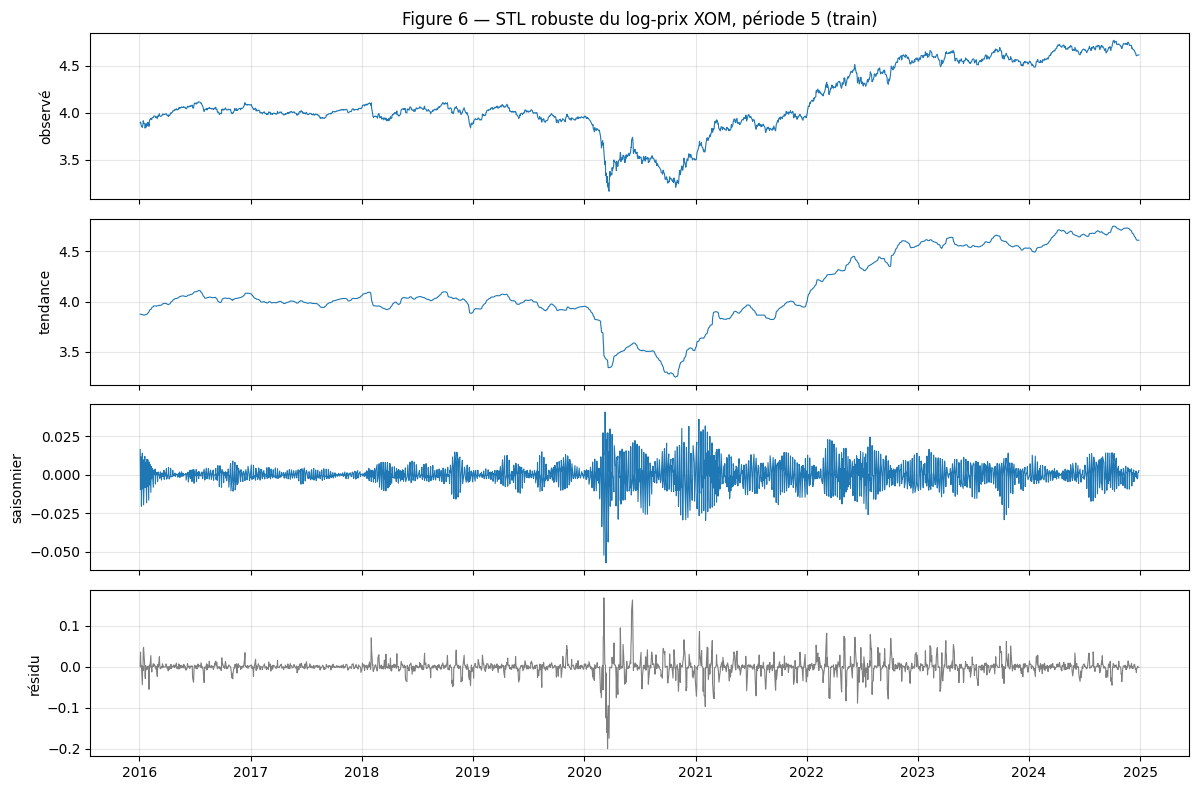

In [23]:
stl5 = eda.stl_decompose(TRAIN["XOM_logp"], 5)
fig = eda.plot_stl(stl5, "Figure 6 — STL robuste du log-prix XOM, période 5 (train)")
save_fig(fig, 6, "stl_xom_p5")
plt.show()

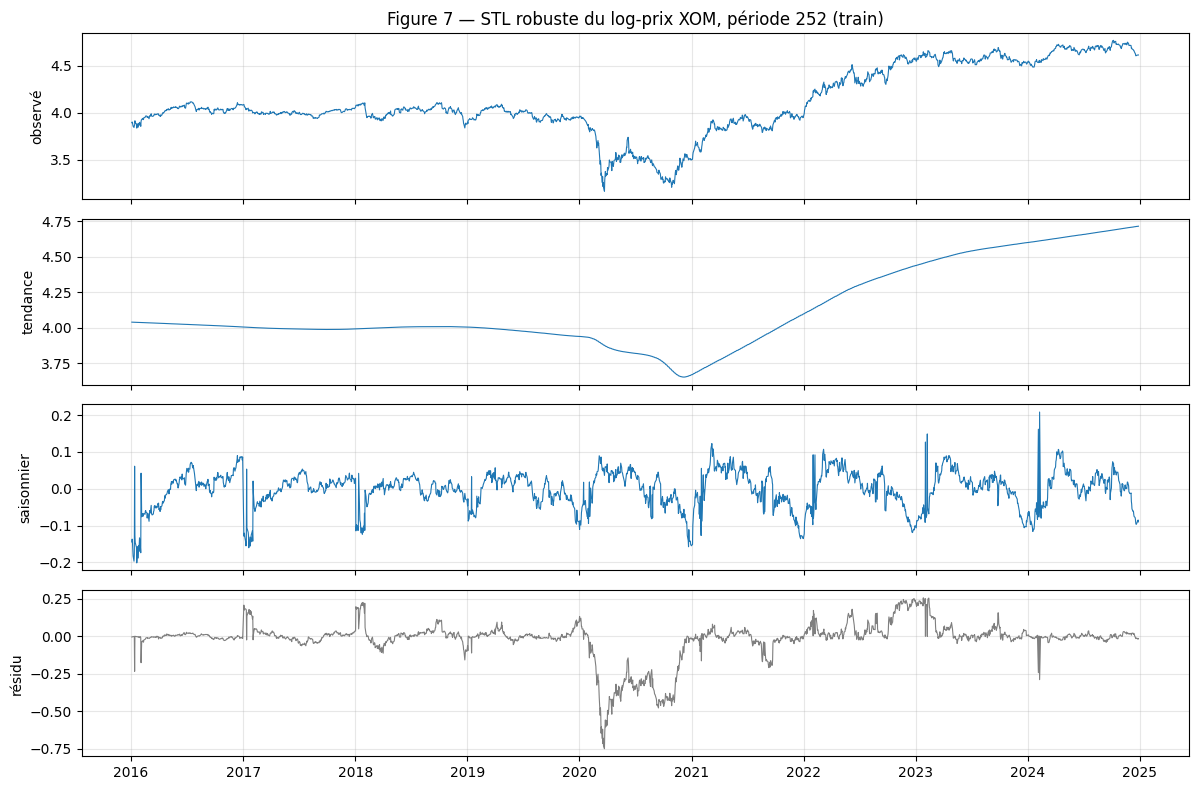

In [24]:
stl252 = eda.stl_decompose(TRAIN["XOM_logp"], 252)
fig = eda.plot_stl(stl252, "Figure 7 — STL robuste du log-prix XOM, période 252 (train)")
save_fig(fig, 7, "stl_xom_p252")
plt.show()

In [25]:
# Contre-vérification de la saisonnalité hebdomadaire directement sur les rendements :
# un effet « jour de la semaine » est la forme que prendrait une saisonnalité s = 5.
for tk in ["XOM", "XLE"]:
    w = eda.weekday_effect(TRAIN[f"{tk}_ret"])
    print(f"{tk} — Kruskal-Wallis (moyennes) : stat = {w['Kruskal-Wallis stat']:.3f}, p = {w['Kruskal-Wallis p']:.4f} ; "
          f"Levene (variances) : stat = {w['Levene stat']:.3f}, p = {w['Levene p']:.4f}")
    display(w["table"].round(3).T)

XOM — Kruskal-Wallis (moyennes) : stat = 2.806, p = 0.5909 ; Levene (variances) : stat = 1.275, p = 0.2775


,lundi,mardi,mercredi,jeudi,vendredi
mean,0.1130,0.0630,-0.0180,0.0190,-0.0110
std,2.0280,1.7320,1.7540,1.7090,1.7070
count,419.0000,465.0000,463.0000,458.0000,456.0000


XLE — Kruskal-Wallis (moyennes) : stat = 1.735, p = 0.7843 ; Levene (variances) : stat = 2.592, p = 0.0350


,lundi,mardi,mercredi,jeudi,vendredi
mean,0.0650,0.0480,-0.0170,-0.0140,0.0780
std,2.3520,1.7580,1.9470,1.7820,1.7490
count,419.0000,465.0000,463.0000,458.0000,456.0000


**Interprétation de la décomposition STL.**

**Force des composantes (tableau).** La tendance domine dans tous les cas : F_T = 0,997 (période 5), 0,991 (21) et 0,869 (252) pour XOM, avec des valeurs proches pour XLE. La saisonnalité est **inexistante** : F_S = 0,000, 0,032 et 0,000 pour XOM, et 0,000, 0,020 et 0,001 pour XLE. Aucune période testée ne fait apparaître de cycle exploitable.

**Figure 6 (période 5).**
- **Tendance.** Elle reproduit fidèlement le log-prix : une phase plate de 2016 à 2019, la chute de 2020, puis la remontée de 2021–2022.
- **« Saisonnalité ».** Une vraie saisonnalité hebdomadaire répéterait le même motif chaque semaine, avec une amplitude stable. Ici, l'amplitude de la composante suit exactement la volatilité : quasi nulle en 2017, maximale le 2020-03-13 (|s| = 0,057). STL a simplement découpé une partie du bruit en blocs de 5 jours.
- **Ordres de grandeur.** L'écart-type de cette composante (0,008) reste bien inférieur à celui du résidu (0,020).
- **Résidu.** Il concentre les chocs de 2020 et a l'allure des rendements.

**Figure 7 (période 252).**
- **Tendance.** Une fenêtre d'un an la rend très lisse.
- **« Saisonnalité ».** La composante ne répète aucun profil annuel identifiable, et ses pics isolés ne reviennent pas à la même date d'une année sur l'autre.
- **Résidu.** Il absorbe le krach de 2020 (jusqu'à −0,75 en log, soit environ −53 %) et des écarts de ±0,25. Son écart-type (0,128) est six fois celui de la décomposition hebdomadaire.

Une décomposition annuelle ne décrit donc pas ces données.

**Contre-vérification directe.** Une saisonnalité de période 5 se traduirait par un effet « jour de la semaine » sur les rendements.
- **Moyenne.** Le lundi a le rendement moyen le plus élevé (0,113 % pour XOM), mais avec l'écart-type le plus fort (2,03 %). Le test de Kruskal-Wallis ne détecte **aucune différence** entre jours (p = 0,59 pour XOM, 0,78 pour XLE).
- **Variance.** Le test de Levene ne rejette pas pour XOM (p = 0,28). Il rejette de justesse pour XLE (p = 0,035), dont le lundi est un peu plus volatil (écart-type de 2,35 % contre 1,75 à 1,95 % les autres jours), ce qui est cohérent avec l'accumulation d'informations pendant le week-end.

Cela concerne la **variance**, pas la moyenne : ce n'est pas un motif qu'un SARIMA pourrait modéliser.

**Conclusion.**
- Il n'y a **pas de saisonnalité** à modéliser : D = 0.
- Le SARIMA de période s = 5 sera estimé en 3.1 pour le vérifier formellement, et devrait être écarté.
- La tendance n'est pas une droite déterministe : elle erre, monte et chute. C'est le comportement d'une tendance **stochastique** (racine unitaire), testée en 2.6.

### 2.5 Valeurs aberrantes

**Méthode.** Un rendement est signalé s'il sort de [Q1 − 3·IQR ; Q3 + 3·IQR], où les quartiles sont calculés sur les **63 jours de bourse précédents** (un trimestre).
- **Seuil glissant plutôt que fixe** : la règle s'adapte au régime de volatilité. Un mouvement de 4 % est banal en mars 2020 mais exceptionnel en 2017.
- **Fenêtre décalée d'un jour** (`shift(1)`) : le jour testé n'influence pas son propre seuil, et la règle n'utilise que le passé.
- **k = 3** (et non 1,5) : avec des queues aussi épaisses, k = 1,5 signalerait des centaines de jours parfaitement ordinaires.

La détection est faite sur toute la période, car la variable indicatrice doit exister aussi sur le test.

In [26]:
out = {tk: eda.detect_outliers(panel[f"{tk}_ret"]) for tk in ["XOM", "XLE"]}
counts = pd.DataFrame({tk: o["outlier"].groupby(o.index.year).sum() for tk, o in out.items()}).fillna(0).astype(int)
counts.loc["total"] = counts.sum()
counts.loc["dont test"] = [int(o.loc[test.index, "outlier"].sum()) for o in out.values()]
both = (out["XOM"]["outlier"] & out["XLE"]["outlier"])
print(f"Jours signalés simultanément pour XOM et XLE : {int(both.sum())}")
counts.T

Jours signalés simultanément pour XOM et XLE : 11


Date,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,total,dont test
XOM,1,0,2,0,10,0,0,0,0,2,15,2
XLE,1,0,2,0,10,0,1,0,0,4,18,4


In [27]:
rows = []
for tk, o in out.items():
    f = o[o["outlier"] == 1]
    rows.append(f.assign(actif=tk, échantillon=np.where(f.index.isin(test.index), "test", "train")))
outliers = pd.concat(rows).reset_index().sort_values(["actif", "Date"])
outliers = outliers[["actif", "Date", "échantillon", "rendement", "borne basse", "borne haute"]]
save_table(outliers, "tab08_outliers", index=False)

# Variables indicatrices sauvegardées pour les modèles (ex. régresseur d'intervention en ARIMAX).
flags = pd.DataFrame({f"{tk}_outlier": o["outlier"] for tk, o in out.items()})
flags.to_csv(ROOT / "data/processed/outliers.csv", lineterminator="\n")
outliers.round(2)

,actif,Date,échantillon,rendement,borne basse,borne haute
15,XLE,2016-11-30,train,4.9600,-4.3800,4.2800
16,XLE,2018-02-02,train,-4.2700,-3.5500,4.0100
17,XLE,2018-02-05,train,-4.2900,-3.6100,4.0100
18,XLE,2020-02-27,train,-5.5000,-4.7400,4.2800
19,XLE,2020-03-06,train,-5.7800,-5.5500,5.3000
20,XLE,2020-03-09,train,-22.4900,-5.5200,5.0300
21,XLE,2020-03-12,train,-13.3200,-5.9600,5.3600
22,XLE,2020-03-13,train,8.8300,-6.2400,5.5700
23,XLE,2020-03-16,train,-14.6300,-6.6600,6.1300
24,XLE,2020-03-18,train,-15.5000,-6.9000,6.2700


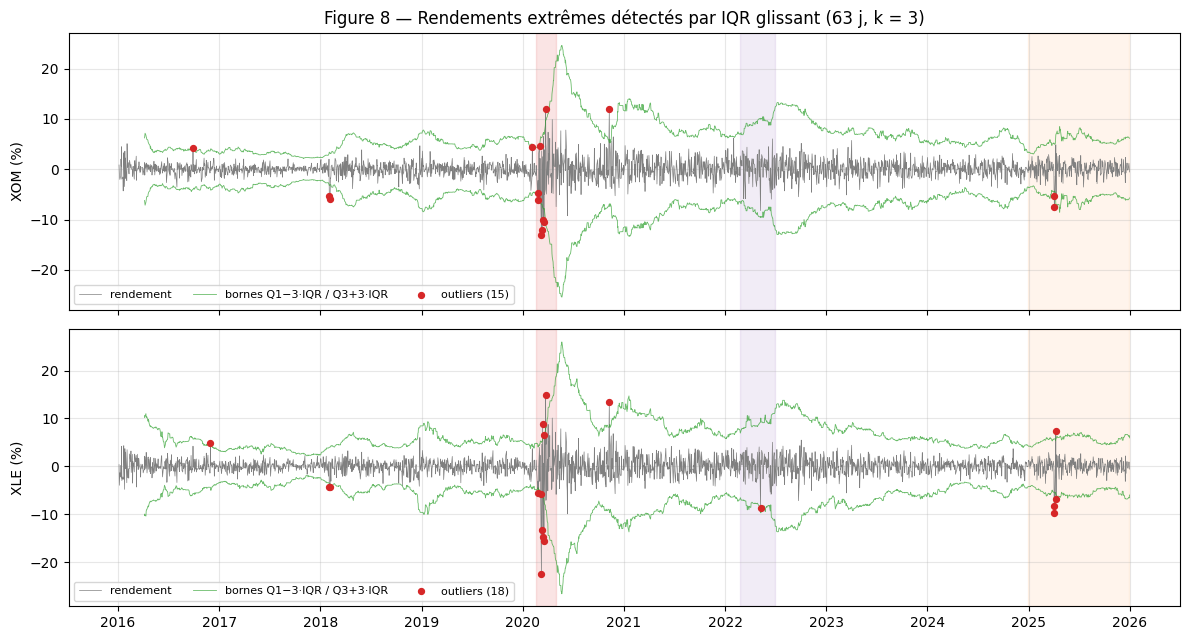

In [28]:
fig, axes = plt.subplots(2, 1, figsize=(12, 6.5), sharex=True)
for ax, (tk, o) in zip(axes, out.items()):
    ax.plot(o.index, o["rendement"], lw=0.5, color="grey", label="rendement")
    ax.plot(o.index, o["borne haute"], lw=0.6, color="tab:green", alpha=0.7, label="bornes Q1−3·IQR / Q3+3·IQR")
    ax.plot(o.index, o["borne basse"], lw=0.6, color="tab:green", alpha=0.7)
    f = o[o["outlier"] == 1]
    ax.scatter(f.index, f["rendement"], color="tab:red", s=18, zorder=3, label=f"outliers ({len(f)})")
    shade(ax)
    ax.set_ylabel(f"{tk} (%)")
    ax.grid(alpha=0.3)
    ax.legend(loc="lower left", fontsize=8, ncol=3)
axes[0].set_title("Figure 8 — Rendements extrêmes détectés par IQR glissant (63 j, k = 3)")
fig.tight_layout()
save_fig(fig, 8, "outliers")
plt.show()

**Interprétation des valeurs aberrantes.**

**Bilan.** On détecte 15 jours extrêmes pour XOM (13 dans le train, 2 dans le test) et 18 pour XLE (14 et 4). **11 jours** sont communs aux deux actifs, ce qui confirme qu'il s'agit de chocs de marché et non d'erreurs de données propres à un titre.

**Concentration en 2020.** Dix jours par actif tombent en 2020. Les plus violents sont :
- **2020-03-09** : −13,0 % pour XOM, −22,5 % pour XLE, face à des bornes de −6,9 % et −5,5 %. Cette date coïncide avec l'effondrement du pétrole lié à la guerre des prix entre l'Arabie saoudite et la Russie, en pleine propagation du COVID-19 ;
- les 12, 16 et 18 mars, puis le rebond du 24 mars (+11,9 % pour XOM, +14,9 % pour XLE) ;
- **2020-11-09** (+11,9 % et +13,3 %), qui coïncide avec l'annonce des premiers résultats d'efficacité d'un vaccin contre le COVID-19.

**Dans le test.** Les jours détectés se concentrent sur **3 au 10 avril 2025** : chute de −7,5 % pour XOM et de −9,7 % pour XLE le 4 avril, puis rebond de +7,5 % pour XLE le 9 avril. Cette période coïncide avec l'annonce, puis la suspension partielle, de nouveaux droits de douane américains.

**Une limite de la règle.** La figure montre qu'après mars 2020 les bornes s'élargissent jusqu'à environ ±25 %, parce que le trimestre précédent était lui-même extrême. Des baisses importantes ne sont donc pas signalées :
- −7,4 % pour XOM le 2020-05-01 (borne à −22,5 %) ;
- −9,2 % pour XOM et −9,9 % pour XLE le 2020-06-11 (bornes à −18,1 % et −20,1 %). Une règle glissante juge chaque jour **par rapport à son régime** : c'est voulu, mais elle réagit avec retard aux changements de régime.

**Traitement retenu : conservation, avec une variable indicatrice.**
1. **Ces chocs sont réels.** Ils correspondent à des événements de marché identifiables et se retrouvent sur les deux actifs. Ce ne sont pas des erreurs de mesure.
2. **Les supprimer ou les lisser sous-estimerait le risque.** La volatilité est justement ce que modélise GARCH : retirer les jours extrêmes ferait disparaître l'objet même de l'étude, et donnerait des intervalles de prévision trop étroits.
3. **Les remplacer serait un choix arbitraire.** Le remplacement par une médiane ou par interpolation créerait des données qui n'ont jamais existé.

Les indicatrices `XOM_outlier` et `XLE_outlier` sont sauvegardées dans `data/processed/outliers.csv`. Elles pourront servir de variables d'intervention (ARIMAX), ou à tester la sensibilité des résultats aux jours extrêmes.

**Sensibilité aux paramètres.** La fenêtre (63 jours) et le seuil (k = 3) sont des choix. On refait la détection sur une grille de 16 réglages, avec des fenêtres de 21, 63, 126 et 252 jours et k = 2 ; 2,5 ; 3 ; 3,5. On regarde ensuite :
- combien de jours chaque réglage signale ;
- quels jours restent signalés quel que soit le réglage : le **noyau**, défini comme les jours signalés par au moins 12 des 16 réglages.

In [29]:
sens = {tk: eda.outlier_sensitivity(panel[f"{tk}_ret"], test.index) for tk in ["XOM", "XLE"]}
grid = pd.concat({tk: g for tk, (g, _) in sens.items()})
save_table(grid, "tab08b_outliers_sensibilite")
grid.unstack("k")["total"]

k            2.0000  2.5000  3.0000  3.5000
    fenêtre                                
XOM 21           65      33      18      11
    63           40      23      15      11
    126          49      26      17      12
    252          54      31      21      15
XLE 21           66      29      14      11
    63           49      30      18      15
    126          59      34      24      16
    252          56      36      27      20

In [30]:
core = pd.concat({tk: c for tk, (_, c) in sens.items()})
core.index.names = ["actif", "Date"]
save_table(core, "tab08c_outliers_noyau")
for tk, (g, c) in sens.items():
    ref = int(out[tk]["outlier"].sum())
    print(f"{tk} : noyau de {len(c)} jours, tous dans la référence : {bool(c['dans la référence'].all())} "
          f"(référence = {ref} jours, dont {ref - len(c)} hors noyau)")
core.round(2)

XOM : noyau de 11 jours, tous dans la référence : True (référence = 15 jours, dont 4 hors noyau)
XLE : noyau de 14 jours, tous dans la référence : True (référence = 18 jours, dont 4 hors noyau)


rendement  réglages qui le signalent  dans la référence
actif Date                                                               
XOM   2018-02-02    -5.2300                         16               True
      2018-02-05    -5.8600                         16               True
      2020-02-27    -6.2100                         14               True
      2020-03-09   -13.0400                         12               True
      2020-03-12   -12.1400                         12               True
      2020-03-16   -10.0100                         12               True
      2020-03-18   -10.5600                         12               True
      2020-03-24    11.9400                         12               True
      2020-11-09    11.9200                         16               True
      2025-04-03    -5.4000                         13               True
      2025-04-04    -7.4700                         16               True
XLE   2018-02-02    -4.2700                         15               True
      2018-02-05    -4.2900                         14               True
      2020-02-27    -5.5000                         12               True
      2020-03-09   -22.4900                         16               True
      2020-03-12   -13.3200                         12               True
      2020-03-13     8.8300                         12               True
      2020-03-16   -14.6300                         13               True
      2020-03-18   -15.5000                         12               True
      2020-03-24    14.8700                         13               True
      2020-11-09    13.3400                         16               True
      2025-04-03    -8.1800                         16               True
      2025-04-04    -9.6500                         16               True
      2025-04-09     7.4600                         16               True
      2025-04-10    -6.7600                         15               True

**Interprétation de la sensibilité.**

**Le nombre de jours signalés dépend beaucoup des paramètres.** Selon le réglage, on obtient de 11 à 65 jours pour XOM et de 11 à 66 pour XLE. Les deux paramètres jouent :
- **k = 2** produit 40 à 66 signalements, dont beaucoup de mouvements ordinaires pour des queues aussi épaisses ;
- **une fenêtre de 21 jours** s'adapte si vite au régime qu'elle ne retrouve qu'environ la moitié des jours de la référence.

Le nombre « 15 outliers » n'a donc pas de valeur absolue : il dépend de la définition retenue.

**Mais les jours importants sont robustes.** Le **noyau**, signalé par au moins 12 des 16 réglages, compte **11 jours pour XOM et 14 pour XLE**, et notre réglage de référence (63 jours, k = 3) les retrouve **tous**. Ce sont :
- les deux séances de début février 2018 ;
- les journées de mars 2020 : le 27 février, puis les 9, 12, 16, 18 et 24 mars, plus le 13 mars pour XLE ;
- le 9 novembre 2020 ;
- avril 2025 : les 3 et 4 avril pour XOM, ainsi que les 9 et 10 pour XLE.

Les **4 jours** de la référence qui restent hors du noyau, pour chaque actif, sont des cas limites dont le statut dépend du réglage :
- XOM : 2016-09-28, 2020-02-05, 2020-02-24, 2020-03-02 ;
- XLE : 2016-11-30, 2020-03-06, 2020-03-19, 2022-05-09.

**Conséquence pratique limitée.** Comme les outliers sont **conservés** dans toutes les estimations, le choix des paramètres n'affecte que la variable indicatrice, pas les données des modèles. Si l'indicatrice est utilisée comme régresseur, il sera prudent de vérifier que les résultats tiennent avec la version « noyau » (`tab08c_outliers_noyau.csv`).

### 2.6 Tests de stationnarité : ADF et KPSS (train)

Les deux tests sont complémentaires car leurs **hypothèses nulles sont opposées** :
- **ADF** (Dickey-Fuller augmenté) : H₀ = la série a une racine unitaire (non stationnaire). Le nombre de retards augmentés est choisi par AIC, pour absorber l'autocorrélation des résidus du test.
- **KPSS** : H₀ = la série est stationnaire (autour d'une constante, ou d'une tendance déterministe dans la spécification « constante + tendance »). Le nombre de retards de la variance de long terme est choisi automatiquement (Hobijn et al., 1998).

Chaque série est testée avec deux spécifications. La spécification « constante + tendance » est la plus exigeante pour le log-prix, qui présente une dérive visible : elle vérifie qu'il ne s'agit pas d'une simple tendance déterministe.
Décision au seuil de 5 % : ADF rejette H₀ si sa statistique est **inférieure** à la valeur critique, KPSS si sa statistique est **supérieure** à la sienne.

In [31]:
stationarity = eda.stationarity_table({
    "XOM log-prix": TRAIN["XOM_logp"], "XOM rendement": TRAIN["XOM_ret"],
    "XLE log-prix": TRAIN["XLE_logp"], "XLE rendement": TRAIN["XLE_ret"],
})
save_table(stationarity, "tab09_adf_kpss")
stationarity.round(4)

ADF stat  ADF VC 5 %  ADF retards   ADF p  ADF rejette H0  KPSS stat  KPSS VC 5 %  KPSS retards  KPSS p  KPSS rejette H0  \
série         spécification                                                                                                                                    
XOM log-prix  constante              -0.9714     -2.8628           18  0.7635           False     3.5632       0.4630            29  < 0.01             True   
              constante + tendance   -1.5995     -3.4124           18  0.7926           False     1.3972       0.1460            29  < 0.01             True   
XOM rendement constante             -10.5566     -2.8628           17  0.0000            True     0.1439       0.4630             8  > 0.10            False   
              constante + tendance  -10.5684     -3.4124           17  0.0000            True     0.0845       0.1460             8  > 0.10            False   
XLE log-prix  constante              -1.5033     -2.8628            7  0.5319           False     3.5858       0.4630            29  < 0.01             True   
              constante + tendance   -1.9726     -3.4124            7  0.6163           False     1.2637       0.1460            29  < 0.01             True   
XLE rendement constante             -16.0638     -2.8628            6  0.0000            True     0.0840       0.4630             9  > 0.10            False   
              constante + tendance  -16.0600     -3.4124            6  0.0000            True     0.0607       0.1460             9  > 0.10            False   

                                                         conclusion  
série         spécification                                          
XOM log-prix  constante             non stationnaire : différencier  
              constante + tendance  non stationnaire : différencier  
XOM rendement constante                                stationnaire  
              constante + tendance                     stationnaire  
XLE log-prix  constante             non stationnaire : différencier  
              constante + tendance  non stationnaire : différencier  
XLE rendement constante                                stationnaire  
              constante + tendance                     stationnaire

**Interprétation des tests ADF et KPSS (train).**

**Log-prix : non stationnaires.**
- **XOM, spécification constante.** L'ADF vaut −0,97, alors que la valeur critique à 5 % est −2,86, avec 18 retards et p = 0,76 : la racine unitaire **n'est pas rejetée**. Le KPSS vaut 3,56, très au-dessus de la valeur critique de 0,463 (p < 0,01) : la stationnarité **est rejetée**.
- **XOM, spécification constante + tendance.** Même verdict : ADF −1,60 contre −3,41 (p = 0,79) ; KPSS 1,40 contre 0,146 (p < 0,01). Le log-prix n'est donc **pas non plus stationnaire autour d'une tendance déterministe**, et retirer une droite ne suffirait pas.
- **XLE.** Résultats identiques : ADF −1,50 (p = 0,53) et −1,97 (p = 0,62) ; KPSS 3,59 et 1,26.
- **Les deux tests concordent** : selon le tableau de décision du plan, conclusion « non stationnaire : différencier ».

**Rendements (log-prix différencié) : stationnaires.**
- **ADF.** La racine unitaire est massivement rejetée : −10,56 pour XOM et −16,06 pour XLE, contre −2,86 (p < 0,0001).
- **KPSS.** La stationnarité n'est pas rejetée : 0,144 pour XOM et 0,084 pour XLE, contre 0,463 (p > 0,10).
- **Les deux spécifications** donnent la même conclusion, et les deux tests concordent : **stationnaire**.

**Fiabilité.** Toutes les statistiques sont loin de leurs valeurs critiques : les conclusions ne dépendent ni du seuil choisi ni de la spécification. Le nombre élevé de retards retenus par AIC (18 pour l'ADF de XOM, 29 pour le KPSS des log-prix) reflète la persistance et l'hétéroscédasticité de la série. Ce choix rend le test robuste à l'autocorrélation, sans changer la décision.

Dernière question : la non-stationnarité du log-prix ne serait-elle qu'un effet du krach de 2020 ?

In [32]:
# Robustesse : la non-stationnarité du log-prix n'est-elle qu'un effet du krach de 2020 ?
za = eda.zivot_andrews_table({"XOM log-prix": TRAIN["XOM_logp"], "XLE log-prix": TRAIN["XLE_logp"]})
save_table(za, "tab10_zivot_andrews")
za.round(4)

statistique  valeur critique 5 %  p-value  retards date de rupture estimée  H0 rejetée (5 %)
série        spécification                                                                                                              
XOM log-prix rupture de niveau                  -3.7940              -4.8107   0.4831       18              2021-12-20             False
             rupture de niveau et de pente      -4.2081              -5.0733   0.3688       18              2020-01-06             False
XLE log-prix rupture de niveau                  -3.9725              -4.8107   0.3685        7              2021-12-20             False
             rupture de niveau et de pente      -4.5680              -5.0733   0.1839        7              2020-01-07             False

**Interprétation du test de Zivot-Andrews.** Une série stationnaire autour d'une tendance qui **casse** une fois peut ressembler à une marche aléatoire, et l'ADF ne rejette alors pas la racine unitaire à tort (Perron, 1989). Zivot-Andrews teste la racine unitaire contre une alternative **stationnaire avec une rupture à date inconnue**, que le test place lui-même.

**Résultat.**
- **Date de rupture.** Le test la place début janvier 2020 (spécification niveau + pente) ou en décembre 2021 (niveau seul), cohérent avec la figure 2.
- **Décision.** Même avec cette rupture, la racine unitaire n'est **pas rejetée** :

  | | Statistique | Valeur critique à 5 % | p-value |
  | --- | --- | --- | --- |
  | XOM | −3,79 / −4,21 | −4,81 / −5,07 | 0,48 / 0,37 |
  | XLE | −3,97 / −4,57 | −4,81 / −5,07 | 0,37 / 0,18 |

**Conclusion.** La non-stationnarité du log-prix n'est pas un artefact du krach de 2020 : c'est une vraie racine unitaire.

### 2.7 Conclusion : ordre de différenciation d = 1

Les éléments convergent tous :

| Indice | Log-prix | Rendements (Δ log-prix) |
| --- | --- | --- |
| Graphique (fig. 1–2) | tendance errante, ruptures | oscillent autour de 0 |
| ACF (fig. 3–4) | ACF(1) = 0,998, décroissance très lente | autocorrélations ≤ 0,13, bruit blanc une fois la volatilité neutralisée |
| ADF (H₀ : racine unitaire) | non rejetée (p ≥ 0,53) | rejetée (p < 0,0001) |
| KPSS (H₀ : stationnaire) | rejetée (p < 0,01) | non rejetée (p > 0,10) |
| Zivot-Andrews (rupture permise) | non rejetée (p ≥ 0,18) | — |
| **Conclusion** | **I(1)** | **I(0)** |

**Les log-prix de XOM et de XLE sont intégrés d'ordre 1 : d = 1.** Une seule différenciation suffit, puisque les rendements sont stationnaires : une seconde différenciation (d = 2) serait une sur-différenciation, qui créerait artificiellement une autocorrélation négative. Il n'y a pas de saisonnalité : D = 0.

**Conséquences pour la section 3.**
1. **ARIMA(p, 1, q) sur le log-prix**, équivalent à un ARMA(p, q) sur les rendements. Le candidat de référence est ARIMA(0,1,0), la marche aléatoire, puisque les rendements sont un bruit blanc en moyenne. La constante sera probablement non significative (t HAC ≈ 0,86 pour XOM, p = 0,39).
2. **SARIMA s = 5** estimé pour la forme, puis écarté : aucune saisonnalité n'a été détectée, ni par STL ni par l'effet jour de la semaine.
3. **VAR sur les rendements** : c'est la version stationnaire des deux séries.
4. **Cointégration sur les log-prix** : les deux séries sont I(1), condition nécessaire pour qu'une combinaison linéaire des deux soit stationnaire. La corrélation de 0,914 et le parallélisme de la figure 2 rendent ce test pertinent.
5. **GARCH sur les rendements** : la variance n'est pas constante (ACF des carrés, kurtosis de 6,6 et 16,4), et une loi de Student est justifiée.